In [1]:
import numpy as np
import torchvision.transforms as transforms
from datasets import load_dataset
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

from accuracy_bounds.classificationproblems.utils import wavelet_array_features
from accuracy_bounds.classificationproblems.feasible_sets import feasible_sets_classification_nn
from accuracy_bounds.classificationproblems.kersize_compute import compute_kernel_size_one_hot

---
## Load the data

In [2]:
hf_train = load_dataset(
    "timm/resisc45",
    split="train",
    cache_dir="data",
)

hf_test = load_dataset(
    "timm/resisc45",
    split="test",
    cache_dir="data")

In [3]:

class RESISC45Dataset(Dataset):
    def __init__(self, hf_dataset, transform=None, n_samples=None, seed=42):
        if n_samples and n_samples < len(hf_dataset):
            hf_dataset = hf_dataset.shuffle(seed=seed).select(range(n_samples))

        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = sample["image"]      # PIL Image
        label = sample["label"]      # integer

        if self.transform:
            image = self.transform(image)

        return image, label

In [4]:

transform = transforms.Compose([
    transforms.ToTensor()
])

print("Train data:", len(hf_train))
print("Test data:", len(hf_test))

Train data: 18900
Test data: 6300


In [5]:
train_data = RESISC45Dataset(hf_train, transform=transform, n_samples=3000, seed=42)
test_data = RESISC45Dataset(hf_test, transform=transform, n_samples=3000, seed=41)
train_loader = DataLoader(train_data, batch_size=256, shuffle=False)
test_loader = DataLoader(test_data, batch_size=256, shuffle=False)

## Average kernel size for one Mickey Mouse image to labels of RESISC45

In [6]:
from collections import Counter

# get labels from the HF dataset
labels = test_data.dataset["label"]

counts = Counter(labels)

M = len(labels)

same_pairs = sum(n * (n - 1) // 2 for n in counts.values())
total_pairs = M * (M - 1) // 2
diff_pairs = total_pairs - same_pairs

average_kersize = 2 * diff_pairs / total_pairs / 2

print(M)
print(counts)
print("Upper accuracy bound:", 1 - 0.5 * average_kersize)

3000
Counter({37: 85, 17: 82, 43: 82, 39: 81, 35: 79, 26: 76, 12: 75, 11: 74, 32: 73, 23: 72, 31: 72, 5: 71, 24: 71, 41: 70, 16: 69, 30: 69, 0: 68, 13: 67, 28: 67, 9: 67, 18: 67, 33: 67, 1: 67, 7: 66, 4: 66, 22: 66, 38: 66, 34: 66, 36: 65, 20: 65, 44: 63, 3: 63, 6: 63, 40: 60, 19: 60, 42: 59, 27: 59, 29: 59, 8: 58, 10: 56, 15: 56, 2: 54, 25: 53, 14: 53, 21: 53})
Upper accuracy bound: 0.511107591419362


## Average kernel size on training set

In [7]:
train_images = []
train_labels = []

for img, label in train_data:
    train_images.append(img.numpy())   # (3,256, 256)
    train_labels.append(label)

train_images = np.stack(train_images)
train_labels = np.array(train_labels)

print(train_images.shape)   # (18900, 3, 256, 256)
print(train_labels.shape)   # (18900,)

(3000, 3, 256, 256)
(3000,)


### Get wavelet features on training set

In [8]:
train_features = wavelet_array_features(train_images, wavelet="haar")

### Compute average kernel size from feasible sets with nearest neighbors and wavelet features induced pseudometric

In [9]:
# N_max is maximum number of neighbors to consider for feasible sets, qx is the quantile for distance threshold
feas = feasible_sets_classification_nn(train_features, train_labels, N_max=200,qx=0.05)
tau_x= feas["tau_x"]
feasible_sets= feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)

In [10]:
print("average_kersize on train set: ", average_kersize)

average_kersize on train set:  0.1587465910038974


### Ablation on quantiles and maximum number of nearest neighbors

In [11]:
train_result_dict = {}

N_list = sorted([10, 20, 30, 40, 50, 100, 200, 300, 450], reverse=True)
qx = 0.05

neighbor_stats = None  # Compute neighbor statistics only once

for N_id, N_max in enumerate(N_list):
    train_result_dict[N_max] = {
        qx: {
            "avg_ker_size": None,
            "tau_x": None,
            "N_k_stats": None
        }
    }

    print(
        f"N_max [{N_id+1}/{len(N_list)}]: {N_max} ...",
        end="\r"
    )

    feas = feasible_sets_classification_nn(
        train_features,
        train_labels,
        N_max=N_max,
        qx=qx,
        neighbor_stats=neighbor_stats
    )

    tau_x = feas["tau_x"]
    feasible_sets = feas["feasible_sets"]
    D_prime = feas["D_prime"]

    if neighbor_stats is None:
        neighbor_stats = {
            "distances": feas["distances"],
            "indices": feas["indices"]
        }

    average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(
        feasible_sets
    )

    train_result_dict[N_max][qx]["avg_ker_size"] = average_kersize
    train_result_dict[N_max][qx]["tau_x"] = tau_x
    train_result_dict[N_max][qx]["N_k_stats"] = Nk_stats

# Extract results in ascending N_max order for convenient comparison
N_list_sorted = sorted(N_list)

average_kersize_list = [
    train_result_dict[N_max][qx]["avg_ker_size"]
    for N_max in N_list_sorted
]

tau_x_list = [
    train_result_dict[N_max][qx]["tau_x"]
    for N_max in N_list_sorted
]

N_k_stats_list = [
    train_result_dict[N_max][qx]["N_k_stats"]
    for N_max in N_list_sorted
]

print("\nN_max values:", N_list_sorted)
print("Average kernel sizes on train set:", average_kersize_list)
print("Tau x values on train set:", tau_x_list)
print("N k statistics on train set:", N_k_stats_list)

N_max [9/9]: 10 ....
N_max values: [10, 20, 30, 40, 50, 100, 200, 300, 450]
Average kernel sizes on train set: [np.float64(0.104453796247589), np.float64(0.13475147825925413), np.float64(0.1499846587147792), np.float64(0.15710617087678025), np.float64(0.1587465910038974), np.float64(0.1587465910038974), np.float64(0.1587465910038974), np.float64(0.1587465910038974), np.float64(0.1587465910038974)]
Tau x values on train set: [31.728962898254395, 31.728962898254395, 31.728962898254395, 31.728962898254395, 31.728962898254395, 31.728962898254395, 31.728962898254395, 31.728962898254395, 31.728962898254395]
N k statistics on train set: [(1, 1.2673333333333334, 1.0, 11), (1, 1.3503333333333334, 1.0, 21), (1, 1.3833333333333333, 1.0, 31), (1, 1.395, 1.0, 41), (1, 1.398, 1.0, 50), (1, 1.398, 1.0, 50), (1, 1.398, 1.0, 50), (1, 1.398, 1.0, 50), (1, 1.398, 1.0, 50)]


## Average kernel size on test set

In [12]:
test_images = []
test_labels = []

for img, label in test_data:
    test_images.append(img.numpy())   # (3,256, 256)
    test_labels.append(label)

test_images = np.stack(test_images)
test_labels = np.array(test_labels)

print(test_images.shape)   # (3000, 3, 256, 256)
print(test_labels.shape)   # (3000,)

(3000, 3, 256, 256)
(3000,)


### Get wavelet features on test set

In [13]:
test_features = wavelet_array_features(test_images, wavelet="haar")

### Compute average kernel size from feasible sets with nearest neighbors and wavelet features induced pseudometric

In [14]:
feas = feasible_sets_classification_nn(test_features, test_labels, N_max=200,qx=0.05)
tau_x= feas["tau_x"]
feasible_sets= feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
print("Average kernel size on test set: ", average_kersize)

Average kernel size on test set:  0.1687970259016554


### Accuracy of optimal classifier on D prime test

In [15]:
def compute_accuracy_star(feasible_sets):
    """Compute Acc_* for a collection of feasible sets."""
    return sum(
        max(np.bincount(Y.astype(int)))
        for Y in feasible_sets if len(Y)
    ) / sum(len(Y) for Y in feasible_sets)


Acc = compute_accuracy_star(feasible_sets)
print("Best accuracy on constructed test dataset", Acc)

Best accuracy on constructed test dataset 0.8977420755536257


### Ablation on quantiles and maximum number of nearest neighbors

In [16]:
test_result_dict = {}

N_list = sorted([10, 20, 30, 40, 50, 100, 200, 300, 450], reverse=True)
qx = 0.05

neighbor_stats = None  # Compute neighbor statistics only once

for N_id, N_max in enumerate(N_list):
    test_result_dict[N_max] = {
        qx: {
            "avg_ker_size": None,
            "tau_x": None,
            "N_k_stats": None
        }
    }

    print(
        f"N_max [{N_id+1}/{len(N_list)}]: {N_max} ...",
        end="\r"
    )

    feas = feasible_sets_classification_nn(
        test_features,
        test_labels,
        N_max=N_max,
        qx=qx,
        neighbor_stats=neighbor_stats
    )

    tau_x = feas["tau_x"]
    feasible_sets = feas["feasible_sets"]
    D_prime = feas["D_prime"]

    if neighbor_stats is None:
        neighbor_stats = {
            "distances": feas["distances"],
            "indices": feas["indices"]
        }

    average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(
        feasible_sets
    )

    test_result_dict[N_max][qx]["avg_ker_size"] = average_kersize
    test_result_dict[N_max][qx]["tau_x"] = tau_x
    test_result_dict[N_max][qx]["N_k_stats"] = Nk_stats

# Extract results in ascending N_max order
N_list_sorted = sorted(N_list)

average_kersize_list = [
    test_result_dict[N_max][qx]["avg_ker_size"]
    for N_max in N_list_sorted
]

tau_x_list = [
    test_result_dict[N_max][qx]["tau_x"]
    for N_max in N_list_sorted
]

N_k_stats_list = [
    test_result_dict[N_max][qx]["N_k_stats"]
    for N_max in N_list_sorted
]

print("\nN_max values:", N_list_sorted)
print("Average kernel sizes on test set:", average_kersize_list)
print("Tau x values on test set:", tau_x_list)
print("N k statistics on test set:", N_k_stats_list)

N_max [9/9]: 10 ....
N_max values: [10, 20, 30, 40, 50, 100, 200, 300, 450]
Average kernel sizes on test set: [np.float64(0.08705902650915441), np.float64(0.12044380779619515), np.float64(0.14275748121317394), np.float64(0.159462001331405), np.float64(0.16508866013958884), np.float64(0.1687970259016554), np.float64(0.1687970259016554), np.float64(0.1687970259016554), np.float64(0.1687970259016554)]
Tau x values on test set: [31.64512004852295, 31.64512004852295, 31.64512004852295, 31.64512004852295, 31.64512004852295, 31.64512004852295, 31.64512004852295, 31.64512004852295, 31.64512004852295]
N k statistics on test set: [(1, 1.3033333333333332, 1.0, 11), (1, 1.4163333333333334, 1.0, 21), (1, 1.473, 1.0, 31), (1, 1.5126666666666666, 1.0, 41), (1, 1.5276666666666667, 1.0, 51), (1, 1.5353333333333334, 1.0, 66), (1, 1.5353333333333334, 1.0, 66), (1, 1.5353333333333334, 1.0, 66), (1, 1.5353333333333334, 1.0, 66)]


## Visualize Feasible Sets

In [17]:
# generate feasible sets on test set for visualization
# N_max is maximum number of neighbors to consider for feasible sets, qx is the quantile for distance threshold
feas = feasible_sets_classification_nn(test_features, test_labels, test_images, N_max=200,qx=0.05, ext_d = True)
tau_x= feas["tau_x"]
feasible_sets= feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

In [18]:

def show_neighbor_pairs(test_images, indices, distances, tau_x, num_pairs=5, labels=None):
    """
    Visualize pairs of images that are nearest neighbors within tau_x.
    If `labels` is provided (a list/array of class names or label indices,
    one per image in test_images), it's included in each subplot title.
    """
    pairs = []
    # loop over anchor images
    for i in range(len(test_images)):
        for idx, dist in zip(indices[i], distances[i]):
            if dist <= tau_x and i != idx:
                pairs.append((i, idx, dist))
    # plot pairs
    fig, axes = plt.subplots(num_pairs, 2, figsize=(6, 3 * num_pairs))
    if num_pairs == 1:
        axes = np.expand_dims(axes, 0)
    np.random.shuffle(pairs)
    pairs = pairs[:min(len(pairs), num_pairs)]
    for row, (i, j, dist) in enumerate(pairs):
        img1 = np.transpose(test_images[i], (1, 2, 0))
        img2 = np.transpose(test_images[j], (1, 2, 0))
        title1 = f"Anchor i={i}"
        title2 = f"Neighbor j={j}, d={dist:.3f}"
        if labels is not None:
            title1 += f"\nlabel={labels[i]}"
            title2 += f"\nlabel={labels[j]}"
        axes[row, 0].imshow(img1)
        axes[row, 0].set_title(title1)
        axes[row, 0].axis("off")
        axes[row, 1].imshow(img2)
        axes[row, 1].set_title(title2)
        axes[row, 1].axis("off")
    plt.tight_layout()
    plt.show()


def show_class_neighbor_grid(test_images, indices, distances, labels, num_neighbors=10, classes=None):
    """
    Build a grid with one row per class. For each class, pick a random
    anchor image from that class and plot its `num_neighbors` closest
    neighbors (columns) based on precomputed `indices`/`distances`.

    Parameters
    ----------
    test_images : array-like, shape (N, 3, H, W)
    indices : array-like, shape (N, k) - neighbor indices per image (e.g. from a NN search)
    distances : array-like, shape (N, k) - corresponding distances
    labels : array-like, shape (N,) - class label (int or str) per image, used to
             pick one random anchor per class
    num_neighbors : int, number of closest neighbors to show per row (default 10)
    classes : optional list mapping label index -> class name, used for row titles
    """
    num_neighbors += 1 # first image should be original 
    labels = np.asarray(labels)
    unique_classes = np.unique(labels)
    num_classes = len(unique_classes)

    fig, axes = plt.subplots(num_classes, num_neighbors,
                              figsize=(2 * num_neighbors, 2 * num_classes))
    if num_classes == 1:
        axes = np.expand_dims(axes, 0)
    if num_neighbors == 1:
        axes = np.expand_dims(axes, 1)

    for row, cls in enumerate(unique_classes):
        # pick a random anchor belonging to this class
        cls_pool = np.where(labels == cls)[0]
        anchor = np.random.choice(cls_pool)

        # get neighbors sorted by distance, excluding the anchor itself
        neighbor_idx = np.array(indices[anchor])
        neighbor_dist = np.array(distances[anchor])
        order = np.argsort(neighbor_dist)
        neighbor_idx = neighbor_idx[order]
        neighbor_dist = neighbor_dist[order]

        neighbor_idx = neighbor_idx[:num_neighbors]
        neighbor_dist = neighbor_dist[:num_neighbors]

        class_name = classes[cls] if classes is not None else cls

        for col in range(num_neighbors):
            ax = axes[row, col]
            if col < len(neighbor_idx):
                j = neighbor_idx[col]
                dist = neighbor_dist[col]
                img = np.transpose(test_images[j], (1, 2, 0))
                ax.imshow(img)
                title = f"d={dist:.3f}"
                if col == 0:
                    title = f"class={class_name}\nanchor={anchor}\n" + title
                ax.set_title(title, fontsize=8)
            ax.axis("off")

    plt.tight_layout()
    plt.show()

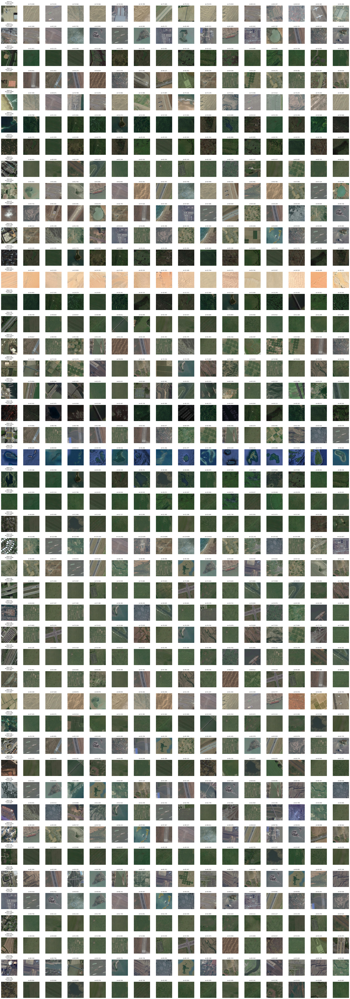

In [19]:
show_class_neighbor_grid(test_images, 
                         indices, 
                         distances, 
                         labels=test_labels, 
                         num_neighbors=15, 
                         classes=None)

## Plot Wavelet Decomposition


In [20]:
import matplotlib.pyplot as plt
import pywt
import numpy as np

def plot_wavelet_decomposition(img, wavelet='haar'):
    """
    Plot CIFAR-10 RGB image + wavelet decomposition per channel.

    img: (3, 32, 32)
    """

    if hasattr(img, "numpy"):
        img = img.numpy()

    channel_names = ['Red', 'Green', 'Blue']

    fig, axes = plt.subplots(3, 5, figsize=(15, 8))

    for c in range(3):

        # --- RGB image ---
        rgb = np.transpose(img, (1, 2, 0))

        axes[c, 0].imshow(rgb)
        axes[c, 0].set_title(f"Original RGB ({channel_names[c]} row)")

        # Add a clear row label on the left side
        axes[c, 0].set_ylabel(
            f"{channel_names[c]} channel",
            rotation=90,
            labelpad=10,
            fontsize=12
        )

        # --- Wavelet transform ---
        LL, (LH, HL, HH) = pywt.dwt2(img[c], wavelet)

        axes[c, 1].imshow(LL, cmap='gray')
        axes[c, 1].set_title(f'LL ({channel_names[c]})')

        axes[c, 2].imshow(LH, cmap='gray')
        axes[c, 2].set_title(f'LH ({channel_names[c]})')

        axes[c, 3].imshow(HL, cmap='gray')
        axes[c, 3].set_title(f'HL ({channel_names[c]})')

        axes[c, 4].imshow(HH, cmap='gray')
        axes[c, 4].set_title(f'HH ({channel_names[c]})')

        for j in range(5):
            axes[c, j].axis('off')

    plt.tight_layout()
    plt.show()

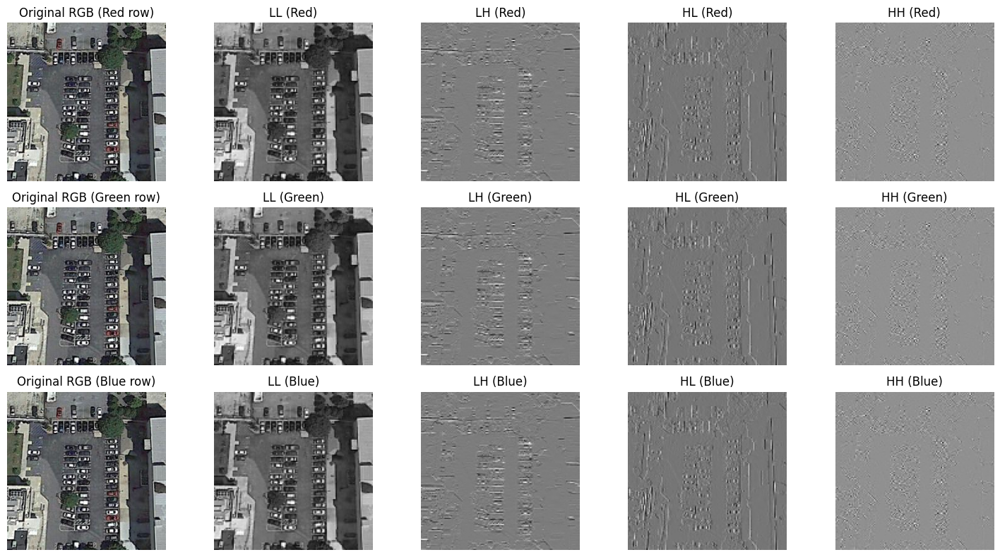

In [21]:
plot_wavelet_decomposition(train_images[1800])